# IND320 Project Part 2

## Reservoir Data Analysis
This notebook presents Part 2 of the IND320 project, building on the reservoir data analysis and Streamlit application developed in Part 1. The project moves beyond local CSV files by retrieving reservoir data directly from the NVE API and introducing electricity flow data from the ENTSO-E API.

The work includes processing and analyzing electricity imports and exports between Norway and Denmark using Apache Spark, storing data in Cassandra and MongoDB Atlas, and further developing the Streamlit application with improved filtering, visualizations, and a new electricity analysis page. The project also incorporates improvements based on feedback received in Part 1.

### Project Links


**GitHub Repository:** https://github.com/dano22222/dano22222/tree/part2-development

**Streamlit Application:** https://ind320-part2-dano22222.streamlit.app/


## 1. Importing reservoir data from the NVE API

The reservoir dataset is retrieved directly from the NVE API instead of a local CSV file. The API response is converted from JSON into a Pandas DataFrame containing 14,922 observations and 11 columns. The first five rows are displayed to inspect the data before further processing and visualization.

In [ ]:
import pandas as pd
import requests
import matplotlib.pyplot as plt

#NVE API endpoint for Norwegian reservoir statistics
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

#requesting data directly from the API
response = requests.get(url, timeout=60)
response.raise_for_status()

#conversion of the JSON response into a Pandas DataFrame
df = pd.DataFrame(response.json())

#displaying the dataset
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (14922, 11)


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


## 2. Renaming the columns

The original dataset contains Norwegian column names. To make the dataset easier to understand and work with, the columns are renamed using clear English names.

In [5]:
#rename the original norwegian columns to clear english names
df = df.rename(columns={
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "year",
    "iso_uke": "week",
    "fyllingsgrad": "fill_level",
    "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "stored_energy_TWh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "fill_level_previous_week",
    "endring_fyllingsgrad": "change_in_fill_level"
})

#check that the new column names were applied correctly
df.head()

,date,area_type,area_number,year,week,fill_level,capacity_TWh,stored_energy_TWh,next_publication_date,fill_level_previous_week,change_in_fill_level
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [ ]:
#to how the different area types
print("Area types:")
print(df["area_type"].value_counts())

#and to show the area numbers belonging to each type
print("\nArea numbers by type:")
for area_type, group in df.groupby("area_type"):
    print(f"{area_type}: {sorted(group['area_number'].unique())}")

Area types:
area_type
EL      8290
VASS    4974
NO      1658
Name: count, dtype: int64

Area numbers by type:
EL: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
NO: [np.int64(0)]
VASS: [np.int64(1), np.int64(2), np.int64(3)]


## 3. Exploring the dataset

Before creating visualizations, it is useful to examine the size, structure and data types of the dataset. This provides an overview of the available variables and helps identify how the data should be handled in the following analysis.

In [7]:
#show the number of rows and columns in the dataset
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

#inspect column names, data types and missing values
df.info()

Number of rows: 14922
Number of columns: 11
<class 'pandas.DataFrame'>
RangeIndex: 14922 entries, 0 to 14921
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   date                      14922 non-null  str    
 1   area_type                 14922 non-null  str    
 2   area_number               14922 non-null  int64  
 3   year                      14922 non-null  int64  
 4   week                      14922 non-null  int64  
 5   fill_level                14922 non-null  float64
 6   capacity_TWh              14922 non-null  float64
 7   stored_energy_TWh         14922 non-null  float64
 8   next_publication_date     14922 non-null  str    
 9   fill_level_previous_week  14922 non-null  float64
 10  change_in_fill_level      14922 non-null  float64
dtypes: float64(5), int64(3), str(3)
memory usage: 1.7 MB


## 4. Displaying the data

The dataset retrieved from the NVE API contains 14,922 observations and 11 variables. To get a clearer overview of the reservoir data, the first ten observations are displayed below.

In [8]:
#display the first ten observations for a closer look at the data
display(df.head(10))

,date,area_type,area_number,year,week,fill_level,capacity_TWh,stored_energy_TWh,next_publication_date,fill_level_previous_week,change_in_fill_level
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301
5,2017-11-05,EL,4,2017,44,0.794520,21.079208,16.747847,0001-01-01T00:00:00,0.804085,-0.009565
6,2000-11-26,EL,4,2000,47,0.866371,21.079208,18.262426,0001-01-01T00:00:00,0.884963,-0.018591
7,2016-09-04,EL,1,2016,35,0.890967,6.003264,5.348708,0001-01-01T00:00:00,0.881946,0.009021
8,2023-08-13,EL,5,2023,32,0.836849,17.390587,14.553301,2023-08-23T13:00:00,0.776765,0.060084
9,2011-09-04,EL,3,2011,35,0.881907,8.920932,7.867432,0001-01-01T00:00:00,0.875135,0.006772


## 5. Visualizing individual columns

To better understand the dataset, the relevant numerical variables are visualized separately. The data is sorted by date before plotting so that changes over time are displayed chronologically.

In [9]:
#convert the date column to datetime and sort the data chronologically
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date")

df.head()

,date,area_type,area_number,year,week,fill_level,capacity_TWh,stored_energy_TWh,next_publication_date,fill_level_previous_week,change_in_fill_level
3111,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
11344,1995-01-08,VASS,2,1995,1,0.608856,23.237715,14.148431,0001-01-01T00:00:00,0.744693,-0.135837
11170,1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,0001-01-01T00:00:00,0.661432,-0.094525
14499,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041
9678,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0001-01-01T00:00:00,0.752631,-0.144643


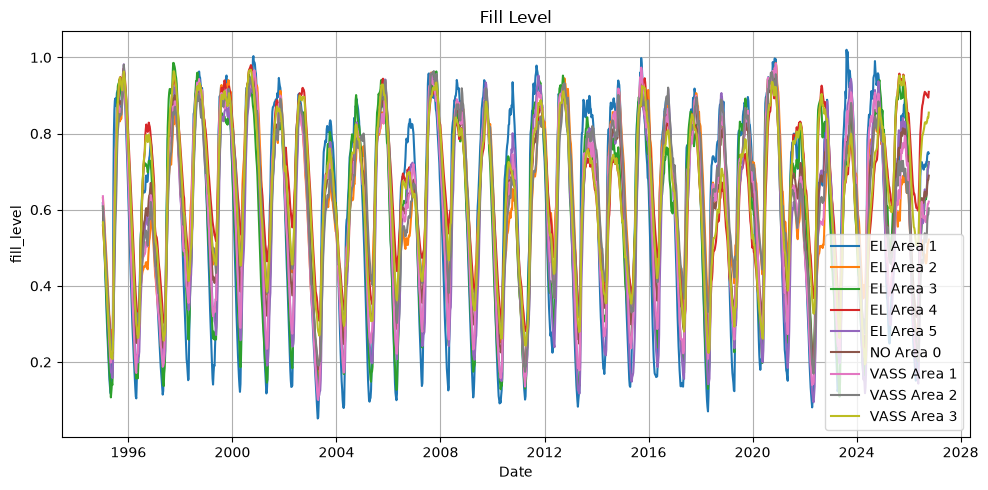

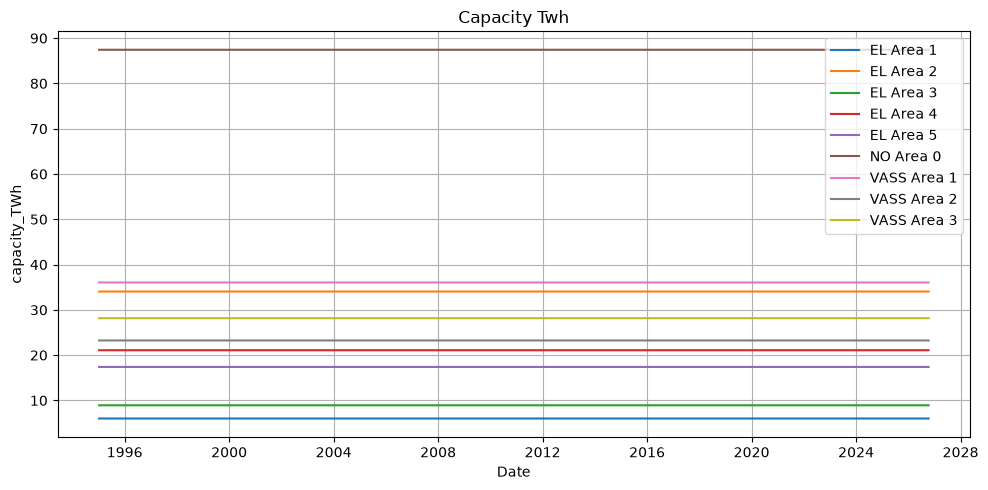

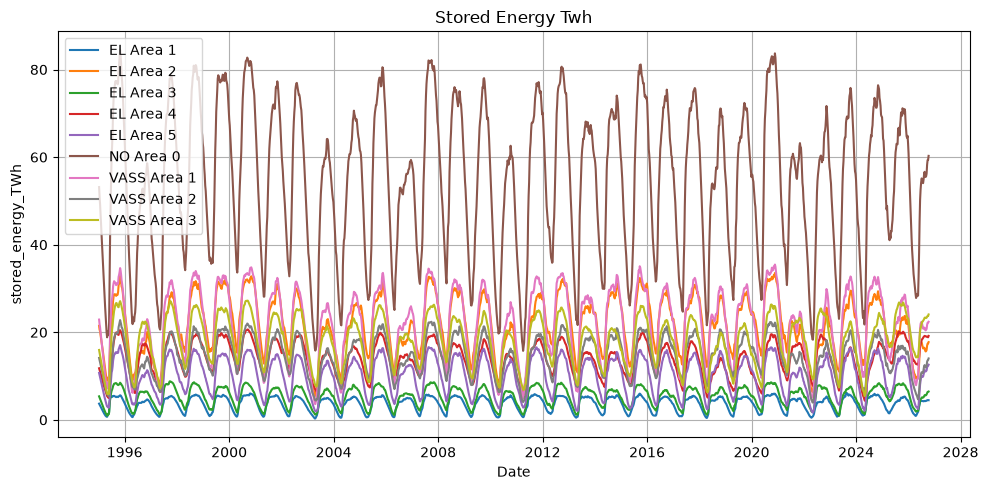

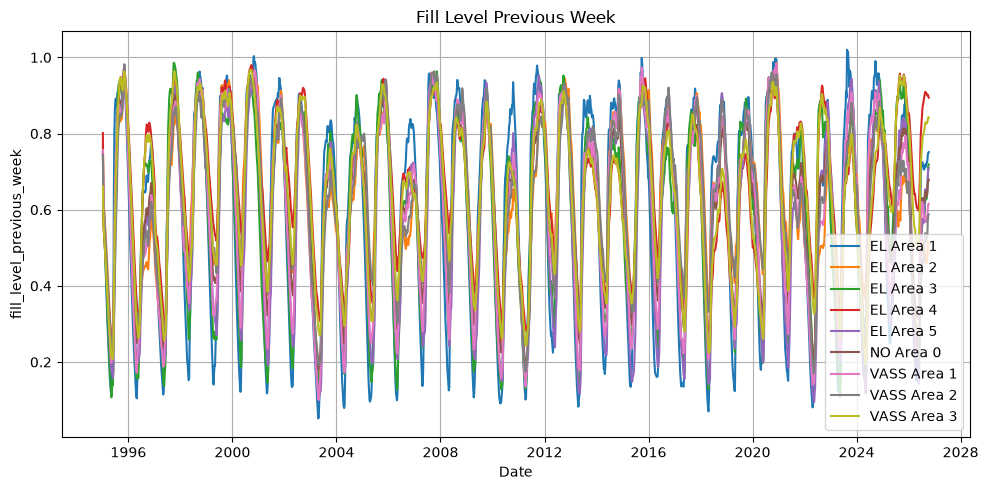

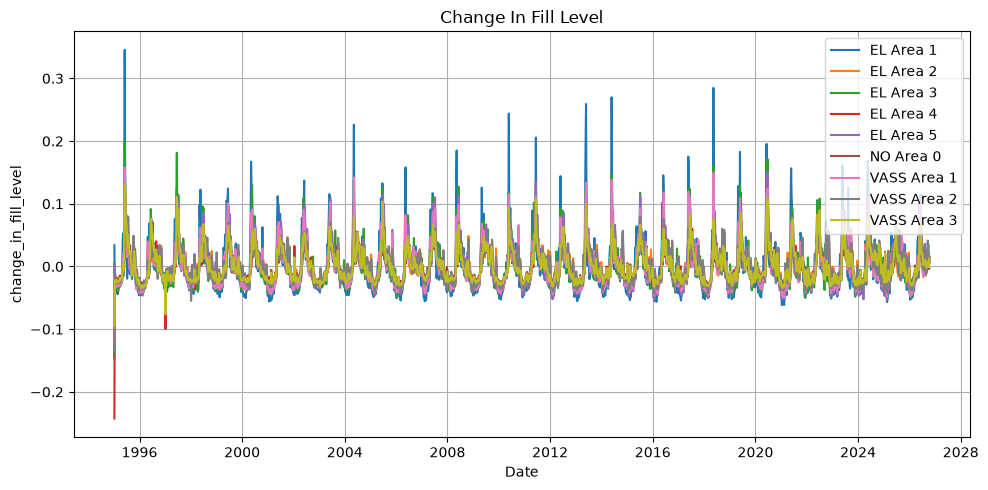

In [ ]:

#selecting the numerical reservoir variables to visualize
numeric_columns = [
    "fill_level",
    "capacity_TWh",
    "stored_energy_TWh",
    "fill_level_previous_week",
    "change_in_fill_level"
]

#plotting each numerical variable separately for every reservoir area
for column in numeric_columns:
    plt.figure(figsize=(10, 5))

    #separating the areas by both area type and area number
    for area_type, area in sorted(
        df[["area_type", "area_number"]]
        .drop_duplicates()
        .itertuples(index=False, name=None)
    ):
        area_data = df[
            (df["area_type"] == area_type) &
            (df["area_number"] == area)
        ].sort_values("date")

        plt.plot(
            area_data["date"],
            area_data[column],
            label=f"{area_type} Area {area}"
        )

    #adding labels, title, legend and grid to each plot
    plt.xlabel("Date")
    plt.ylabel(column)
    plt.title(column.replace("_", " ").title())
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


## 6. Visualizing all numerical columns together

Since the numerical variables have different units and scales, they are normalized before being plotted together. This makes it possible to compare their development over time in a single figure.

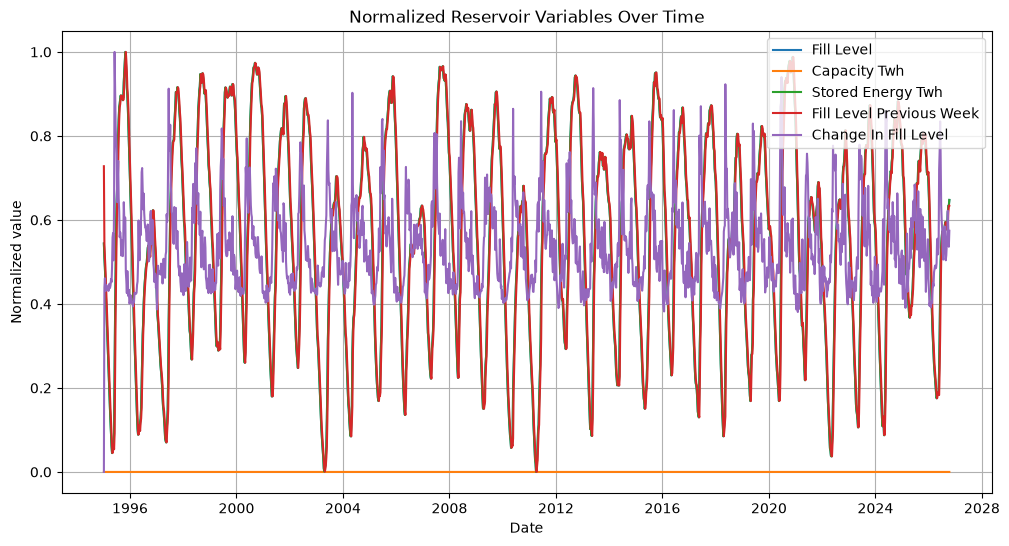

In [ ]:
#select the numerical variables to compare
columns_to_plot = [
    "fill_level",
    "capacity_TWh",
    "stored_energy_TWh",
    "fill_level_previous_week",
    "change_in_fill_level"
]

#use of national reservoir data (Area 0) for comparison
plot_data = df[
    (df["area_type"] == "NO") &
    (df["area_number"] == 0)
].set_index("date")[columns_to_plot].sort_index()

#handling constant variables to avoid division by zero
ranges = plot_data.max() - plot_data.min()
normalized_df = (plot_data - plot_data.min()) / ranges.replace(0, 1)

#plotting all normalized variables together
plt.figure(figsize=(12, 6))

for column in normalized_df.columns:
    plt.plot(
        normalized_df.index,
        normalized_df[column],
        label=column.replace("_", " ").title()
    )

#adding labels, title, legend and grid to the plot
plt.xlabel("Date")
plt.ylabel("Normalized value")
plt.title("Normalized Reservoir Variables Over Time")
plt.legend()
plt.grid(True)
plt.show()

## 7. Setting up and testing Apache Spark

In [ ]:
import os

#load the Cassandra Connector when Spark starts
os.environ["PYSPARK_SUBMIT_ARGS"] = (
    "--packages com.datastax.spark:spark-cassandra-connector_2.12:3.5.1 "
    "pyspark-shell"
)

from pyspark.sql import SparkSession

#creating a Spark session connected to local Cassandra
spark = (
    SparkSession.builder
    .appName("IND320 Part 2")
    .master("local[*]")
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .config("spark.cassandra.connection.port", "9042")
    .config("spark.cassandra.connection.localDC", "datacenter1")
    .getOrCreate()
)

#verifying the connector configuration
print("Spark version:", spark.version)
print(
    "Configured packages:",
    spark.sparkContext.getConf().get("spark.jars.packages", "NOT SET")
)


In [ ]:
#testing the Spark connection to the IND320 Cassandra database
cassandra_test = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(keyspace="ind320", table="connection_test")
    .load()
)


#displaying the test data
cassandra_test.show(truncate=False)

+---+-------------------------------+
|id |message                        |
+---+-------------------------------+
|1  |Spark Cassandra connection test|
+---+-------------------------------+



In [ ]:
#checking the Spark configuration and loaded connector files
print(
    "Configured packages:",
    spark.sparkContext.getConf().get("spark.jars.packages", "NOT SET")
)

print(
    "Loaded JAR files:",
    spark.sparkContext._jsc.sc().listJars().toString()
)


## 8. Connecting to MongoDB Atlas

In [15]:
from urllib.parse import urlsplit
import os
from dotenv import load_dotenv

load_dotenv(".env", override=True)

uri = os.getenv("MONGODB_URI", "")
print("MongoDB hostname:", urlsplit(uri).hostname)

MongoDB hostname: ind320-cluster.wwxppks.mongodb.net


In [ ]:
import dns.resolver

#use of Google's public DNS server for this Python session
resolver = dns.resolver.Resolver(configure=False)
resolver.nameservers = ["8.8.8.8"]
resolver.timeout = 5
resolver.lifetime = 15

#testing DNS resolution for MongoDB Atlas
records = resolver.resolve(
    "_mongodb._tcp.ind320-cluster.wwxppks.mongodb.net",
    "SRV"
)

for record in records:
    print(record)

dns.resolver.default_resolver = resolver
dns.resolver.get_default_resolver = lambda: resolver

0 0 27017 ac-yyotwue-shard-00-01.wwxppks.mongodb.net.
0 0 27017 ac-yyotwue-shard-00-02.wwxppks.mongodb.net.
0 0 27017 ac-yyotwue-shard-00-00.wwxppks.mongodb.net.


In [ ]:
import os
from dotenv import load_dotenv
from pymongo import MongoClient

#loading the MongoDB connection string from the local .env file
load_dotenv(".env", override=True)

mongodb_uri = os.getenv("MONGODB_URI")

if not mongodb_uri:
    raise ValueError("MONGODB_URI was not found in the .env file.")

#connecting to MongoDB Atlas
client = MongoClient(mongodb_uri, serverSelectionTimeoutMS=10000)

#a test of the connection
client.admin.command("ping")

print("Successfully connected to MongoDB Atlas!")

Successfully connected to MongoDB Atlas!


In [ ]:
import os
import requests
from dotenv import load_dotenv

#loading the ENTSO-E API token
load_dotenv(".env", override=True)
token = os.getenv("ENTSOE_API_TOKEN")

if not token:
    raise ValueError("ENTSOE_API_TOKEN was not found in .env")

#retrieve actual electricity consumption for NO1
url = "https://web-api.tp.entsoe.eu/api"

params = {
    "securityToken": token,
    "documentType": "A65",
    "processType": "A16",
    "outBiddingZone_Domain": "10YNO-1--------2",
    "periodStart": "202610090000",
    "periodEnd": "202610100000"
}

response = requests.get(url, params=params, timeout=30)

print("HTTP status:", response.status_code)
print("Response preview:")
print(response.text[:400])

## 9. ENTSO-E Cross-Border Electricity Flows

This section retrieves cross-border electricity flow data
between Norway and neighbouring countries using the ENTSO-E API.

The data will be processed using Apache Spark and stored
in Cassandra before further analysis and visualization.

In [ ]:

import os
import requests
import xml.etree.ElementTree as ET
from dotenv import load_dotenv

#loading the API token securely
load_dotenv(".env", override=True)
token = os.getenv("ENTSOE_API_TOKEN")

if not token:
    raise ValueError("ENTSOE_API_TOKEN was not found in .env")

#ENTSO-E bidding zone identifiers
NO2 = "10YNO-2--------T"
DK1 = "10YDK-1--------W"

url = "https://web-api.tp.entsoe.eu/api"

#test one day of cross border flows in both directions
directions = {
    "Export NO2 to DK1": (NO2, DK1),
    "Import DK1 to NO2": (DK1, NO2)
}

for direction, (out_domain, in_domain) in directions.items():

    params = {
        "securityToken": token,
        "documentType": "A11",
        "out_Domain": out_domain,
        "in_Domain": in_domain,
        "periodStart": "202510010000",
        "periodEnd": "202510020000"
    }

    response = requests.get(url, params=params, timeout=30)

    print(f"\n{direction}")
    print("HTTP status:", response.status_code)

    response.raise_for_status()

    #parse the XML response
    root = ET.fromstring(response.content)
 
    if root.tag.endswith("Acknowledgement_MarketDocument"):
        print("API message:", response.text[:500])
        continue

    time_series = root.findall(".//{*}TimeSeries")
    points = root.findall(".//{*}Point")

    print("Time series:", len(time_series))
    print("Data points:", len(points))

    #display a few example measurements
    for point in points[:5]:
        position = point.findtext("{*}position")
        quantity = point.findtext("{*}quantity")
        print(f"Position {position}: {quantity} MW")



Export NO2 to DK1
HTTP status: 200
Time series: 1
Data points: 96
Position 1: 1069.79 MW
Position 2: 1070.04 MW
Position 3: 1083.06 MW
Position 4: 1261.11 MW
Position 5: 1321.06 MW

Import DK1 to NO2
HTTP status: 200
Time series: 1
Data points: 1
Position 1: 0 MW


In [ ]:

import pandas as pd
from datetime import datetime, timedelta

#converting ENTSO-E API responses into a structured DataFrame
flow_rows = []

for direction, (out_domain, in_domain) in directions.items():

    params = {
        "securityToken": token,
        "documentType": "A11",
        "out_Domain": out_domain,
        "in_Domain": in_domain,
        "periodStart": "202510010000",
        "periodEnd": "202510020000"
    }

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()
    root = ET.fromstring(response.content)

    for series in root.findall(".//{*}TimeSeries"):

        curve_type = series.findtext("{*}curveType")

        for period in series.findall("{*}Period"):

            start_text = period.findtext(
                "{*}timeInterval/{*}start"
            )
            end_text = period.findtext(
                "{*}timeInterval/{*}end"
            )
            resolution = period.findtext("{*}resolution")

            start_time = datetime.fromisoformat(
                start_text.replace("Z", "+00:00")
            )

            print(
                direction,
                "| Resolution:", resolution,
                "| Curve:", curve_type,
                "| Period:", start_text, "to", end_text
            )

            #converting the time resolution into minutes
            resolution_minutes = {
                "PT15M": 15,
                "PT30M": 30,
                "PT60M": 60
            }.get(resolution)

            if resolution_minutes is None:
                raise ValueError(
                    f"Unsupported resolution: {resolution}"
                )

            for point in period.findall("{*}Point"):
                position = int(
                    point.findtext("{*}position")
                )
                quantity = float(
                    point.findtext("{*}quantity")
                )

                timestamp = start_time + timedelta(
                    minutes=(position - 1) * resolution_minutes
                )

                flow_rows.append({
                    "timestamp": timestamp,
                    "connection": "NO2-DK1",
                    "direction": direction,
                    "power_MW": quantity,
                    "resolution_minutes": resolution_minutes
                })

flow_df = pd.DataFrame(flow_rows)

#sort and inspect the retrieved data
flow_df = flow_df.sort_values(
    ["timestamp", "direction"]
).reset_index(drop=True)

display(flow_df.head(10))

print("\nNumber of rows:", len(flow_df))
print("\nRows per direction:")
print(flow_df.groupby("direction").size())


Export NO2 to DK1 | Resolution: PT15M | Curve: A03 | Period: 2025-10-01T00:00Z to 2025-10-02T00:00Z
Import DK1 to NO2 | Resolution: PT15M | Curve: A03 | Period: 2025-10-01T00:00Z to 2025-10-02T00:00Z


,timestamp,connection,direction,power_MW,resolution_minutes
0,2025-10-01 00:00:00+00:00,NO2-DK1,Export NO2 to DK1,1069.79,15
1,2025-10-01 00:00:00+00:00,NO2-DK1,Import DK1 to NO2,0.00,15
2,2025-10-01 00:15:00+00:00,NO2-DK1,Export NO2 to DK1,1070.04,15
3,2025-10-01 00:30:00+00:00,NO2-DK1,Export NO2 to DK1,1083.06,15
4,2025-10-01 00:45:00+00:00,NO2-DK1,Export NO2 to DK1,1261.11,15
5,2025-10-01 01:00:00+00:00,NO2-DK1,Export NO2 to DK1,1321.06,15
6,2025-10-01 01:15:00+00:00,NO2-DK1,Export NO2 to DK1,1510.88,15
7,2025-10-01 01:30:00+00:00,NO2-DK1,Export NO2 to DK1,1612.13,15
8,2025-10-01 01:45:00+00:00,NO2-DK1,Export NO2 to DK1,1533.02,15
9,2025-10-01 02:00:00+00:00,NO2-DK1,Export NO2 to DK1,1327.15,15



Number of rows: 97

Rows per direction:
direction
Export NO2 to DK1    96
Import DK1 to NO2     1
dtype: int64


In [ ]:

#expanding the A03 variable sized blocks to 15 minute intervals

day_start = pd.Timestamp("2025-10-01T00:00:00Z")
day_end = pd.Timestamp("2025-10-02T00:00:00Z")

full_times = pd.date_range(
    start=day_start,
    end=day_end,
    freq="15min",
    inclusive="left"
)

expanded_data = []

for direction, group in flow_df.groupby("direction"):

    group = group.sort_values("timestamp").set_index("timestamp")

    #to ensure the first block starts at the beginning of the day
    if group.index[0] != day_start:
        raise ValueError(f"Unexpected first timestamp: {direction}")

    #A03 values remain constant until the next reported point
    expanded = group.reindex(full_times, method="ffill")

    expanded["timestamp"] = expanded.index
    expanded["direction"] = direction

    expanded_data.append(expanded.reset_index(drop=True))

flow_full_df = pd.concat(
    expanded_data,
    ignore_index=True
).sort_values(["timestamp", "direction"]).reset_index(drop=True)

#converting power (MW) into energy (MWh) per 15-minute interval
flow_full_df["energy_MWh"] = (
    flow_full_df["power_MW"] * 15 / 60
)

print("Total rows:", len(flow_full_df))
print("\nRows per direction:")
print(flow_full_df.groupby("direction").size())

print("\nTotal energy (MWh):")
print(flow_full_df.groupby("direction")["energy_MWh"].sum())

display(flow_full_df.head(10))


Total rows: 192

Rows per direction:
direction
Export NO2 to DK1    96
Import DK1 to NO2    96
dtype: int64

Total energy (MWh):
direction
Export NO2 to DK1    35976.6525
Import DK1 to NO2        0.0000
Name: energy_MWh, dtype: float64


,connection,direction,power_MW,resolution_minutes,timestamp,energy_MWh
0,NO2-DK1,Export NO2 to DK1,1069.79,15,2025-10-01 00:00:00+00:00,267.4475
1,NO2-DK1,Import DK1 to NO2,0.00,15,2025-10-01 00:00:00+00:00,0.0000
2,NO2-DK1,Export NO2 to DK1,1070.04,15,2025-10-01 00:15:00+00:00,267.5100
3,NO2-DK1,Import DK1 to NO2,0.00,15,2025-10-01 00:15:00+00:00,0.0000
4,NO2-DK1,Export NO2 to DK1,1083.06,15,2025-10-01 00:30:00+00:00,270.7650
5,NO2-DK1,Import DK1 to NO2,0.00,15,2025-10-01 00:30:00+00:00,0.0000
6,NO2-DK1,Export NO2 to DK1,1261.11,15,2025-10-01 00:45:00+00:00,315.2775
7,NO2-DK1,Import DK1 to NO2,0.00,15,2025-10-01 00:45:00+00:00,0.0000
8,NO2-DK1,Export NO2 to DK1,1321.06,15,2025-10-01 01:00:00+00:00,330.2650
9,NO2-DK1,Import DK1 to NO2,0.00,15,2025-10-01 01:00:00+00:00,0.0000


In [ ]:

import pandas as pd
import requests
import xml.etree.ElementTree as ET

def fetch_cross_border_flow(out_domain, in_domain, direction,
                            period_start, period_end):

    params = {
        "securityToken": token,
        "documentType": "A11",
        "out_Domain": out_domain,
        "in_Domain": in_domain,
        "periodStart": period_start,
        "periodEnd": period_end
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()
    root = ET.fromstring(response.content)

    if root.tag.endswith("Acknowledgement_MarketDocument"):
        raise ValueError(f"ENTSO-E returned: {response.text[:500]}")

    rows = []

    for series in root.findall(".//{*}TimeSeries"):
        curve_type = series.findtext("{*}curveType")

        for period in series.findall("{*}Period"):

            start = pd.to_datetime(
                period.findtext("{*}timeInterval/{*}start"),
                utc=True
            )
            end = pd.to_datetime(
                period.findtext("{*}timeInterval/{*}end"),
                utc=True
            )

            resolution = period.findtext("{*}resolution")
            minutes = {
                "PT15M": 15,
                "PT30M": 30,
                "PT60M": 60
            }.get(resolution)

            if minutes is None:
                raise ValueError(f"Unknown resolution: {resolution}")

            timestamps = pd.date_range(
                start, end, freq=f"{minutes}min",
                inclusive="left"
            )

            values = {}
            for point in period.findall("{*}Point"):
                position = int(point.findtext("{*}position"))
                quantity = float(point.findtext("{*}quantity"))

                timestamp = start + pd.Timedelta(
                    minutes=(position - 1) * minutes
                )
                values[timestamp] = quantity

            power = pd.Series(values, dtype=float)

            #A03, each value remains valid until the next point
            if curve_type == "A03":
                power = power.reindex(timestamps).ffill()
            else:
                power = power.reindex(timestamps)

            if power.isna().any():
                raise ValueError(
                    f"Missing measurements for {direction}"
                )

            for timestamp, mw in power.items():
                rows.append({
                    "timestamp": timestamp,
                    "connection": "NO2-DK1",
                    "direction": direction,
                    "power_MW": mw,
                    "energy_MWh": mw * minutes / 60
                })

    if not rows:
        raise ValueError(f"No flow data returned for {direction}")

    return pd.DataFrame(rows)


#retrieve January 2025 in both directions
monthly_frames = []

for direction, (out_domain, in_domain) in directions.items():
    df = fetch_cross_border_flow(
        out_domain,
        in_domain,
        direction,
        "202501010000",
        "202502010000"
    )
    monthly_frames.append(df)

january_df = pd.concat(
    monthly_frames, ignore_index=True
).sort_values(["timestamp", "direction"])

print("Total rows:", len(january_df))
print("\nRows per direction:")
print(january_df.groupby("direction").size())

print("\nTotal energy (MWh):")
print(january_df.groupby("direction")["energy_MWh"].sum())

display(january_df.head(10))


Total rows: 1488

Rows per direction:
direction
Export NO2 to DK1    744
Import DK1 to NO2    744
dtype: int64

Total energy (MWh):
direction
Export NO2 to DK1    762042.750
Import DK1 to NO2     91769.725
Name: energy_MWh, dtype: float64


,timestamp,connection,direction,power_MW,energy_MWh
0,2025-01-01 00:00:00+00:00,NO2-DK1,Export NO2 to DK1,0.0000,0.0000
744,2025-01-01 00:00:00+00:00,NO2-DK1,Import DK1 to NO2,1603.9600,1603.9600
1,2025-01-01 01:00:00+00:00,NO2-DK1,Export NO2 to DK1,0.0000,0.0000
745,2025-01-01 01:00:00+00:00,NO2-DK1,Import DK1 to NO2,1585.1300,1585.1300
2,2025-01-01 02:00:00+00:00,NO2-DK1,Export NO2 to DK1,0.0000,0.0000
746,2025-01-01 02:00:00+00:00,NO2-DK1,Import DK1 to NO2,1330.3925,1330.3925
3,2025-01-01 03:00:00+00:00,NO2-DK1,Export NO2 to DK1,0.0000,0.0000
747,2025-01-01 03:00:00+00:00,NO2-DK1,Import DK1 to NO2,1237.3875,1237.3875
4,2025-01-01 04:00:00+00:00,NO2-DK1,Export NO2 to DK1,0.0000,0.0000
748,2025-01-01 04:00:00+00:00,NO2-DK1,Import DK1 to NO2,1200.2150,1200.2150


In [ ]:

#retrieve one year of cross border electricity flow data

year_df = fetch_cross_border_flow(
    out_domain=NO2,
    in_domain=DK1,
    direction="Export NO2 to DK1",
    period_start="202410120000",
    period_end="202510120000"
)

print("Number of observations:", len(year_df))
print("First timestamp:", year_df["timestamp"].min())
print("Last timestamp:", year_df["timestamp"].max())
print("Total energy (MWh):", year_df["energy_MWh"].sum())

display(year_df.head())


Number of observations: 22224
First timestamp: 2024-10-12 00:00:00+00:00
Last timestamp: 2025-10-11 23:45:00+00:00
Total energy (MWh): 8364544.254999999


,timestamp,connection,direction,power_MW,energy_MWh
0,2024-10-12 00:00:00+00:00,NO2-DK1,Export NO2 to DK1,1499.71,1499.71
1,2024-10-12 01:00:00+00:00,NO2-DK1,Export NO2 to DK1,1620.74,1620.74
2,2024-10-12 02:00:00+00:00,NO2-DK1,Export NO2 to DK1,1631.26,1631.26
3,2024-10-12 03:00:00+00:00,NO2-DK1,Export NO2 to DK1,1630.16,1630.16
4,2024-10-12 04:00:00+00:00,NO2-DK1,Export NO2 to DK1,1624.19,1624.19


In [ ]:

#retrieve two years of cross border electricity flows in both directions between NO2 and DK1

periods = [
    ("202410120000", "202510120000"),
    ("202510120000", "202610120000")
]

all_frames = []

for start, end in periods:
    for direction, (out_domain, in_domain) in directions.items():

        print(f"Downloading {direction}: {start} to {end}")

        df = fetch_cross_border_flow(
            out_domain=out_domain,
            in_domain=in_domain,
            direction=direction,
            period_start=start,
            period_end=end
        )

        all_frames.append(df)
        print(f"Retrieved {len(df)} observations")

#combination of all API responses
flow_2y_df = pd.concat(
    all_frames, ignore_index=True
)

flow_2y_df = flow_2y_df.sort_values(
    ["timestamp", "direction"]
).reset_index(drop=True)

#checking that intervals have not been duplicated
duplicates = flow_2y_df.duplicated(
    subset=["timestamp", "connection", "direction"]
).sum()

print("\nDuplicate timestamps:", duplicates)

if duplicates > 0:
    raise ValueError("Overlapping observations detected!")

#inspect time intervals and possible gaps
for direction, group in flow_2y_df.groupby("direction"):
    gaps = (
        group.sort_values("timestamp")["timestamp"]
        .diff()
        .dt.total_seconds()
        .div(60)
        .dropna()
    )

    print(f"\n{direction}")
    print("Interval lengths in minutes:")
    print(gaps.value_counts().head())
    print("Largest interval gap:", gaps.max(), "minutes")

print("\nTotal observations:", len(flow_2y_df))

print("\nTotal energy (MWh):")
print(flow_2y_df.groupby("direction")["energy_MWh"].sum())

display(flow_2y_df.head(10))


Retrieved 22224 observations
Retrieved 22224 observations
Retrieved 35040 observations
Retrieved 35040 observations

Duplicate timestamps: 0

Export NO2 to DK1
Interval lengths in minutes:
timestamp
15.0    52991
60.0     4272
Name: count, dtype: int64
Largest interval gap: 60.0 minutes

Import DK1 to NO2
Interval lengths in minutes:
timestamp
15.0    52991
60.0     4272
Name: count, dtype: int64
Largest interval gap: 60.0 minutes

Total observations: 114528

Total energy (MWh):
direction
Export NO2 to DK1    1.397653e+07
Import DK1 to NO2    3.985708e+06
Name: energy_MWh, dtype: float64


,timestamp,connection,direction,power_MW,energy_MWh
0,2024-10-12 00:00:00+00:00,NO2-DK1,Export NO2 to DK1,1499.71,1499.71
1,2024-10-12 00:00:00+00:00,NO2-DK1,Import DK1 to NO2,0.00,0.00
2,2024-10-12 01:00:00+00:00,NO2-DK1,Export NO2 to DK1,1620.74,1620.74
3,2024-10-12 01:00:00+00:00,NO2-DK1,Import DK1 to NO2,0.00,0.00
4,2024-10-12 02:00:00+00:00,NO2-DK1,Export NO2 to DK1,1631.26,1631.26
5,2024-10-12 02:00:00+00:00,NO2-DK1,Import DK1 to NO2,0.00,0.00
6,2024-10-12 03:00:00+00:00,NO2-DK1,Export NO2 to DK1,1630.16,1630.16
7,2024-10-12 03:00:00+00:00,NO2-DK1,Import DK1 to NO2,0.00,0.00
8,2024-10-12 04:00:00+00:00,NO2-DK1,Export NO2 to DK1,1624.19,1624.19
9,2024-10-12 04:00:00+00:00,NO2-DK1,Import DK1 to NO2,0.00,0.00


In [ ]:
from pyspark.sql import SparkSession

#starting Apache Spark with the Cassandra connector
spark = (
    SparkSession.builder
    .appName("IND320 Part 2")
    .master("local[*]")
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    )
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .config("spark.cassandra.connection.port", "9042")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)

#verifying that Spark works
print("Spark version:", spark.version)
print("Spark test:", spark.range(1).count())


In [ ]:

import pandas as pd
from pyspark.sql import functions as F

#checking that the existing Spark session works
print("Spark version:", spark.version)
print("Spark test:", spark.range(1).count())

#then use UTC consistently when processing timestamps
spark.conf.set("spark.sql.session.timeZone", "UTC")

#preparing ENTSO-E data for the Cassandra table
data = flow_2y_df.copy()

data["timestamp"] = pd.to_datetime(
    data["timestamp"], utc=True
)

data["year_month"] = data["timestamp"].dt.strftime("%Y-%m")

#keep the timestamps as strings with an explicit UTC offset
data["timestamp_iso"] = data["timestamp"].dt.strftime(
    "%Y-%m-%dT%H:%M:%S+00:00"
)

data = data.rename(columns={
    "power_MW": "power_mw",
    "energy_MWh": "energy_mwh"
})

data = data[[
    "connection",
    "direction",
    "year_month",
    "timestamp_iso",
    "power_mw",
    "energy_mwh"
]]

#converting Pandas data into a Spark DataFrame
spark_df = spark.createDataFrame(data.to_dict("records"))

spark_df = spark_df.withColumn(
    "observation_time",
    F.to_timestamp(
        "timestamp_iso",
        "yyyy-MM-dd'T'HH:mm:ssXXX"
    )
).drop("timestamp_iso")

#checking the structure before storing data
spark_df.printSchema()
spark_df.show(5, truncate=False)

#only need to write 10 rows as an initial test
spark_df.limit(10).write \
    .format("org.apache.spark.sql.cassandra") \
    .options(
        table="cross_border_flows",
        keyspace="ind320"
    ) \
    .mode("append") \
    .save()

print("Successfully inserted 10 test rows into Cassandra!")


Spark version: 3.5.1
Spark test: 1
root
 |-- connection: string (nullable = true)
 |-- direction: string (nullable = true)
 |-- energy_mwh: double (nullable = true)
 |-- power_mw: double (nullable = true)
 |-- year_month: string (nullable = true)
 |-- observation_time: timestamp (nullable = true)

+----------+-----------------+----------+--------+----------+-------------------+
|connection|direction        |energy_mwh|power_mw|year_month|observation_time   |
+----------+-----------------+----------+--------+----------+-------------------+
|NO2-DK1   |Export NO2 to DK1|1499.71   |1499.71 |2024-10   |2024-10-12 00:00:00|
|NO2-DK1   |Import DK1 to NO2|0.0       |0.0     |2024-10   |2024-10-12 00:00:00|
|NO2-DK1   |Export NO2 to DK1|1620.74   |1620.74 |2024-10   |2024-10-12 01:00:00|
|NO2-DK1   |Import DK1 to NO2|0.0       |0.0     |2024-10   |2024-10-12 01:00:00|
|NO2-DK1   |Export NO2 to DK1|1631.26   |1631.26 |2024-10   |2024-10-12 02:00:00|
+----------+-----------------+----------+----

26/10/15 02:11:17 WARN TaskSetManager: Stage 10 contains a task of very large size (1079 KiB). The maximum recommended task size is 1000 KiB.


In [ ]:

#storing the complete two-year dataset in Cassandra

print("Rows to insert:", len(flow_2y_df))

#then splitting the workload into smaller partitions
spark_df.repartition(8).write \
    .format("org.apache.spark.sql.cassandra") \
    .options(
        table="cross_border_flows",
        keyspace="ind320"
    ) \
    .mode("append") \
    .save()

print("Successfully stored the complete dataset in Cassandra!")


Rows to insert: 114528


26/10/15 02:11:17 WARN TaskSetManager: Stage 13 contains a task of very large size (1079 KiB). The maximum recommended task size is 1000 KiB.


Successfully stored the complete dataset in Cassandra!


In [ ]:

#this is to read the stored data back from Cassandra using Spark

cassandra_df = spark.read \
    .format("org.apache.spark.sql.cassandra") \
    .options(
        table="cross_border_flows",
        keyspace="ind320"
    ) \
    .load()

stored_rows = cassandra_df.count()
expected_rows = len(flow_2y_df)

print("Expected rows:", expected_rows)
print("Rows in Cassandra:", stored_rows)
print("All rows stored:", stored_rows == expected_rows)

cassandra_df.show(5, truncate=False)


Expected rows: 114528
Rows in Cassandra: 114528
All rows stored: True
+----------+-----------------+----------+-------------------+-----------------+--------+
|connection|direction        |year_month|observation_time   |energy_mwh       |power_mw|
+----------+-----------------+----------+-------------------+-----------------+--------+
|NO2-DK1   |Export NO2 to DK1|2025-09   |2025-09-01 00:00:00|314.0075         |1256.03 |
|NO2-DK1   |Export NO2 to DK1|2025-09   |2025-09-01 00:15:00|307.1050000000001|1228.42 |
|NO2-DK1   |Export NO2 to DK1|2025-09   |2025-09-01 00:30:00|334.57           |1338.28 |
|NO2-DK1   |Export NO2 to DK1|2025-09   |2025-09-01 00:45:00|330.725          |1322.9  |
|NO2-DK1   |Export NO2 to DK1|2025-09   |2025-09-01 01:00:00|270.2875         |1081.15 |
+----------+-----------------+----------+-------------------+-----------------+--------+
only showing top 5 rows



## 10. Data Analysis and Visualization Using Spark

This section extracts relevant electricity flow data from
Cassandra using Apache Spark and visualizes electricity
imports and exports between Norway and Denmark.

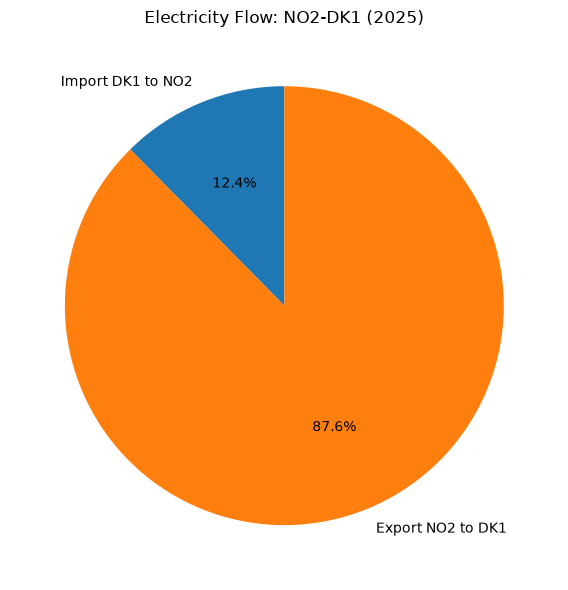

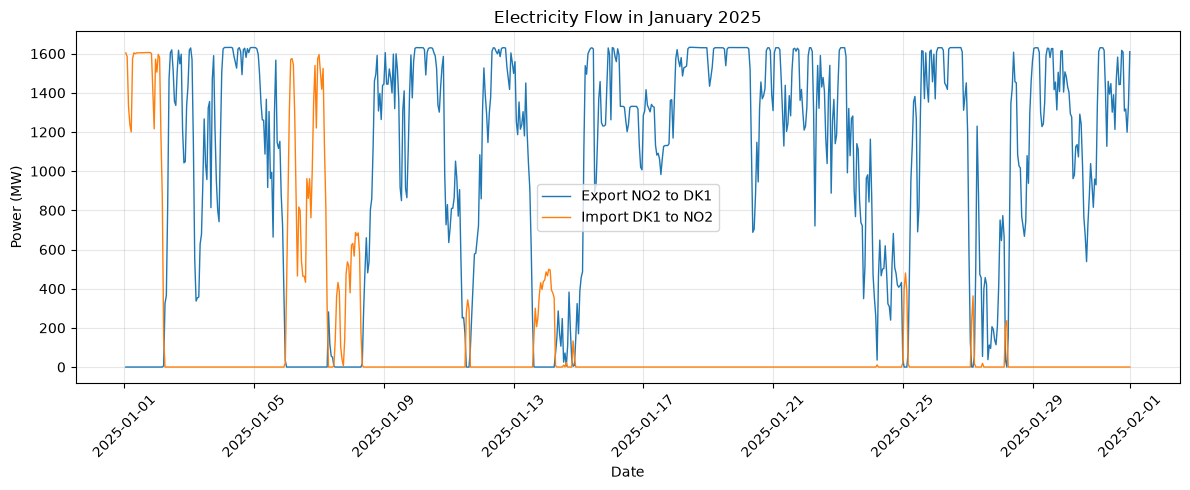

Spark data extraction and visualization completed.


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

#selecting a connection and a complete calendar year
selected_connection = "NO2-DK1"
selected_year = 2025

#extract the required columns and filter using Spark
selected_df = (
    cassandra_df
    .select(
        "connection",
        "direction",
        "observation_time",
        "power_mw",
        "energy_mwh"
    )
    .filter(F.col("connection") == selected_connection)
    .filter(F.year("observation_time") == selected_year)
)

#pie chart: total energy imported and exported during 2025
yearly_totals = (
    selected_df
    .groupBy("direction")
    .agg(F.sum("energy_mwh").alias("total_mwh"))
    .collect()
)

labels = [row["direction"] for row in yearly_totals]
values = [row["total_mwh"] for row in yearly_totals]

plt.figure(figsize=(7, 6))
plt.pie(
    values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90
)
plt.title(f"Electricity Flow: {selected_connection} ({selected_year})")
plt.tight_layout()
plt.show()

#line chart: hourly or 15 minute power values in January
january_rows = (
    selected_df
    .filter(F.month("observation_time") == 1)
    .select("observation_time", "direction", "power_mw")
    .orderBy("observation_time")
    .collect()
)

january_pd = pd.DataFrame(
    [row.asDict() for row in january_rows]
)

plt.figure(figsize=(12, 5))

for direction, group in january_pd.groupby("direction"):
    plt.plot(
        group["observation_time"],
        group["power_mw"],
        label=direction,
        linewidth=1
    )

plt.title(f"Electricity Flow in January {selected_year}")
plt.xlabel("Date")
plt.ylabel("Power (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Spark data extraction and visualization completed.")


## 11. Storing Processed Data in MongoDB

This section transfers selected electricity flow data from
Cassandra through Apache Spark to MongoDB Atlas.

MongoDB will serve as the data source for the Streamlit application.

In [ ]:

import os
from datetime import datetime, timezone
from dotenv import load_dotenv
from pymongo import MongoClient, UpdateOne
from pyspark.sql import functions as F

#connecting securely to MongoDB Atlas
load_dotenv(".env", override=True)

mongo_client = MongoClient(
    os.environ["MONGODB_URI"],
    serverSelectionTimeoutMS=10000
)

mongo_client.admin.command("ping")

#selecting the database and collection
mongo_db = mongo_client["ind320"]
mongo_collection = mongo_db["cross_border_flows"]

#extracting 10 observations from Cassandra using Spark
sample_rows = (
    cassandra_df
    .select(
        "connection",
        "direction",
        "observation_time",
        "power_mw",
        "energy_mwh"
    )
    .orderBy("observation_time")
    .limit(10)
    .withColumn(
        "timestamp_utc",
        F.date_format(
            "observation_time",
            "yyyy-MM-dd'T'HH:mm:ss"
        )
    )
    .collect()
)

#preparation of the MongoDB documents
operations = []

for row in sample_rows:
    timestamp = datetime.fromisoformat(
        row["timestamp_utc"]
    ).replace(tzinfo=timezone.utc)

    document = {
        "connection": row["connection"],
        "direction": row["direction"],
        "timestamp": timestamp,
        "year": timestamp.year,
        "month": timestamp.month,
        "power_mw": float(row["power_mw"]),
        "energy_mwh": float(row["energy_mwh"])
    }

    #the upsert prevents duplicates when rerunning the cell
    operations.append(
        UpdateOne(
            {
                "connection": document["connection"],
                "direction": document["direction"],
                "timestamp": document["timestamp"]
            },
            {"$set": document},
            upsert=True
        )
    )

result = mongo_collection.bulk_write(operations)

print("Successfully connected to MongoDB Atlas!")
print("New documents inserted:", result.upserted_count)
print("Existing documents updated:", result.modified_count)
print("Documents in collection:", mongo_collection.count_documents({}))

#displaying an example without MongoDB's internal ID
example = mongo_collection.find_one({}, {"_id": 0})
print("\nExample document:")
print(example)


Successfully connected to MongoDB Atlas!
New documents inserted: 0
Existing documents updated: 0
Documents in collection: 114528

Example document:
{'connection': 'NO2-DK1', 'direction': 'Import DK1 to NO2', 'timestamp': datetime.datetime(2024, 10, 12, 0, 0), 'energy_mwh': 0.0, 'month': 10, 'power_mw': 0.0, 'year': 2024}


In [ ]:

from datetime import datetime, timezone
from pymongo import UpdateOne
from pyspark.sql import functions as F

#creating a unique index to prevent duplicate observations
mongo_collection.create_index(
    [("connection", 1), ("direction", 1), ("timestamp", 1)],
    unique=True
)

#selecting the required columns from Cassandra using Spark
mongo_source_df = cassandra_df.select(
    "connection",
    "direction",
    "observation_time",
    "power_mw",
    "energy_mwh"
).withColumn(
    "timestamp_utc",
    F.date_format("observation_time", "yyyy-MM-dd'T'HH:mm:ss")
)

#transfering the data in batches to avoid loading everything into memory
batch = []
processed = 0
batch_size = 1000

for row in mongo_source_df.toLocalIterator():

    timestamp = datetime.fromisoformat(
        row["timestamp_utc"]
    ).replace(tzinfo=timezone.utc)

    document = {
        "connection": row["connection"],
        "direction": row["direction"],
        "timestamp": timestamp,
        "year": timestamp.year,
        "month": timestamp.month,
        "power_mw": float(row["power_mw"]),
        "energy_mwh": float(row["energy_mwh"])
    }

    batch.append(
        UpdateOne(
            {
                "connection": document["connection"],
                "direction": document["direction"],
                "timestamp": timestamp
            },
            {"$set": document},
            upsert=True
        )
    )

    if len(batch) >= batch_size:
        mongo_collection.bulk_write(batch, ordered=False)
        processed += len(batch)
        batch = []

        print(f"Processed {processed} observations")

#inserting any remaining observations
if batch:
    mongo_collection.bulk_write(batch, ordered=False)
    processed += len(batch)

print("\nTransfer completed!")
print("Observations processed:", processed)
print(
    "Documents in MongoDB:",
    mongo_collection.count_documents({})
)

print(
    "Matches Cassandra:",
    mongo_collection.count_documents({}) == cassandra_df.count()
)


Processed 1000 observations
Processed 2000 observations
Processed 3000 observations
Processed 4000 observations
Processed 5000 observations
Processed 6000 observations
Processed 7000 observations
Processed 8000 observations
Processed 9000 observations
Processed 10000 observations
Processed 11000 observations
Processed 12000 observations
Processed 13000 observations
Processed 14000 observations
Processed 15000 observations
Processed 16000 observations
Processed 17000 observations
Processed 18000 observations
Processed 19000 observations
Processed 20000 observations
Processed 21000 observations
Processed 22000 observations
Processed 23000 observations
Processed 24000 observations
Processed 25000 observations
Processed 26000 observations
Processed 27000 observations
Processed 28000 observations
Processed 29000 observations
Processed 30000 observations
Processed 31000 observations
Processed 32000 observations
Processed 33000 observations
Processed 34000 observations
Processed 35000 observa

26/10/15 06:01:09 WARN HeartbeatReceiver: Removing executor driver with no recent heartbeats: 947688 ms exceeds timeout 120000 ms
26/10/15 06:01:09 WARN SparkContext: Killing executors is not supported by current scheduler.
26/10/15 06:16:18 ERROR Inbox: Ignoring error
org.apache.spark.SparkException: Exception thrown in awaitResult: 
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:56)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:310)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRefByURI(RpcEnv.scala:102)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRef(RpcEnv.scala:110)
	at org.apache.spark.util.RpcUtils$.makeDriverRef(RpcUtils.scala:36)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.driverEndpoint$lzycompute(BlockManagerMasterEndpoint.scala:124)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.org$apache$spark$storage$BlockManagerMasterEndpoint$$

# ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

## 12. Development Log

Part 2 of the IND320 project focused on extending the work from Part 1 by introducing API connections, Apache Spark, Cassandra, MongoDB Atlas, and further improvements to the Streamlit application. While Part 1 mainly involved analyzing reservoir data from a local CSV file, the goal of Part 2 was to build a more complete data pipeline connecting external data sources, processing, storage, and interactive visualization.

I started by replacing the original CSV file with a direct connection to the NVE API. In Jupyter Notebook, I imported the data into Pandas, renamed Norwegian column names, converted dates, and explored the dataset through tables and visualizations. Based on feedback from Part 1, I also worked on improving the readability of the graphs. Some visualizations had too many overlapping lines, and I was encouraged to introduce clearer filtering options and distinguish between geographical area types and area numbers. I addressed this by separating EL, NO, and VASS and improving how individual reservoir areas could be selected and compared. The graphs also showed recurring seasonal patterns in reservoir filling levels.

The next task involved retrieving approximately two years of cross-border electricity flow data from the ENTSO-E API, focusing on electricity imports and exports between NO2 in Norway and DK1 in Denmark. One challenge was handling different time resolutions, including hourly and 15 minute observations. I examined the timestamps, handled variable-sized intervals, and checked for duplicates before preparing the dataset for further processing.

I then used Docker Desktop to run Cassandra locally and connected it to Apache Spark. This required troubleshooting configuration issues, dependencies, and database connections. After successfully establishing the connection, I stored 114,528 observations in Cassandra and verified that all observations could be retrieved. Using Spark, I extracted the relevant data and created a pie chart showing annual imports and exports, together with a line chart illustrating electricity flows during January 2025. The processed data was subsequently transferred to MongoDB Atlas in batches, and I verified that the document counts matched.

For the Streamlit application, I updated the Data and Plot pages to retrieve reservoir data from the NVE API instead of a local file. I also improved the interactive controls, allowing users to select geographical area types, compare reservoir areas, choose time periods, and download filtered data. A new Electricity page was developed using MongoDB Atlas, with interactive pie and line charts.

Finally, I deployed and tested the updated application on Streamlit Cloud, including its connection to MongoDB Atlas. Overall, this project strengthened my understanding of data pipelines, database integration, and interactive applications, while demonstrating the importance of troubleshooting, testing, and incorporating feedback into further development.

## 13. AI Usage

OpenAI ChatGPT was used as a supporting tool throughout the development of this project, primarily to clarify assignment requirements, explain technical concepts, help with Python programming, and improve the structure and documentation of the Jupyter Notebook and Streamlit application.

In Part 2, ChatGPT was particularly useful when working with the NVE and ENTSO-E APIs, configuring Apache Spark and Cassandra, establishing connections to MongoDB Atlas, and troubleshooting issues during Streamlit Cloud deployment. It was also used to suggest improvements to data processing, visualizations, and interactive features, as well as to support proofreading and language refinement.

All recommendations were reviewed, adapted, and tested before being incorporated into the project. This included checking API responses, validating data transformations, verifying that observations were correctly stored in Cassandra and MongoDB, and testing the functionality of the deployed Streamlit application.

While ChatGPT contributed to solving and development, the final decisions, implementation, testing, and evaluation of the results remained my responsibility.